# HW3 Section 6 Q2d: reading the class handwriting dataset

`class_handwriting.npz` combines the handwriting files that the class submitted with the pre-registration.
The images are shuffled, and the labels and writers are removed.

This notebook shows how to load the file correctly, look at the images, and save your predictions in the required format.
Put `class_handwriting.npz` in the same folder as this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

STUDENT_ID = "113000000"          # change to your student ID
PATH = "class_handwriting.npz"

## 1. Load the file

The file has one array, `images`: a `uint8` array of shape `N × 28 × 28 × 3` (RGB, values 0 to 255, dark ink on light paper).
This is the same format as your own `HW3_handwriting_{student_id}.npz`, except that there are no `labels`.

In [2]:
data = np.load(PATH)
print("arrays in the file:", data.files)

images = data["images"]
print("shape:", images.shape, " dtype:", images.dtype, " min/max:", images.min(), images.max())

assert images.ndim == 4 and images.shape[1:] == (28, 28, 3), "expected N x 28 x 28 x 3"
assert images.dtype == np.uint8, "expected uint8"
N = len(images)
print("number of images N =", N)

arrays in the file: ['images']
shape: (4320, 28, 28, 3)  dtype: uint8  min/max: 0 255
number of images N = 4320


**Common mistakes**
- `np.load` returns a lazy `NpzFile`. Read the array with `data["images"]`; there is no `data["labels"]`.
- Do not reorder, filter, or deduplicate the images. Prediction `i` must be for `images[i]`.
- The images are stored as raw RGB, **before** any preprocessing. Apply exactly the same conversion you used for your own handwriting in Q2a (and the same normalization as your training data) before you feed them to your network.

## 2. Look at the images

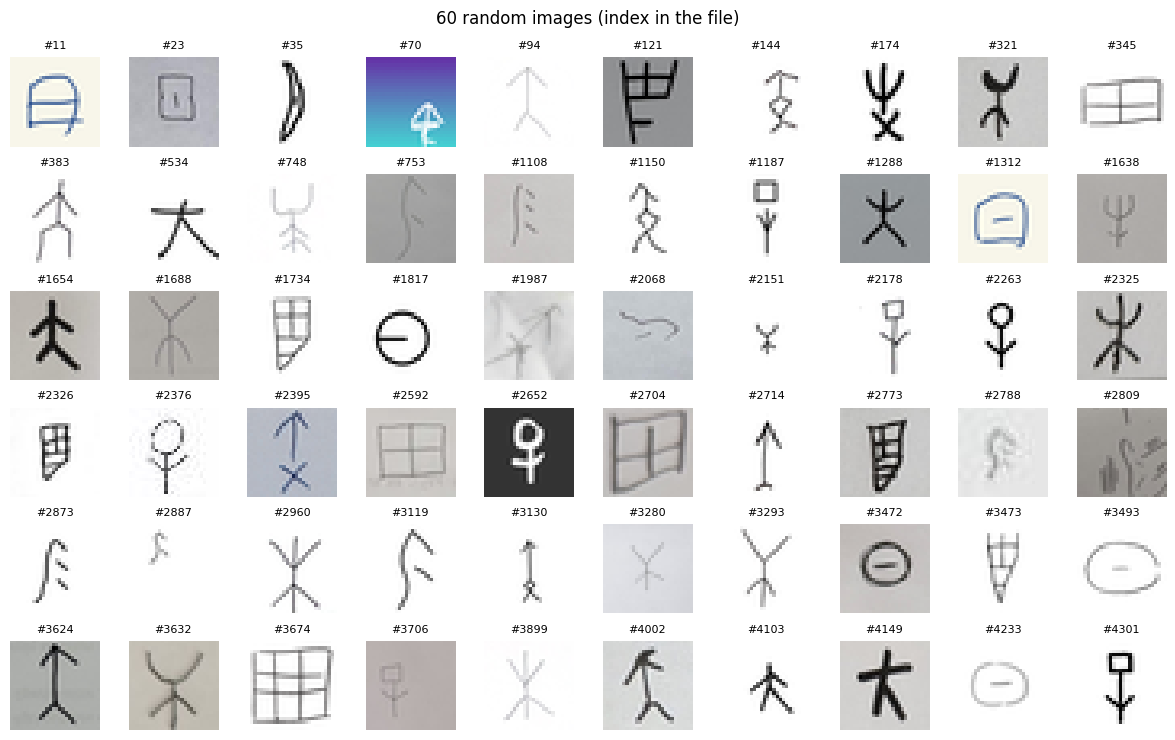

In [3]:
rng = np.random.default_rng(0)
idx = np.sort(rng.choice(N, 60, replace=False))

fig, axes = plt.subplots(6, 10, figsize=(12, 7.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(images[i])
    ax.set_title(f"#{i}", fontsize=8)
    ax.axis("off")
fig.suptitle("60 random images (index in the file)")
plt.tight_layout()
plt.show()

The first 30 images in file order. Neighbouring images come from different writers and different classes, because the file is shuffled.

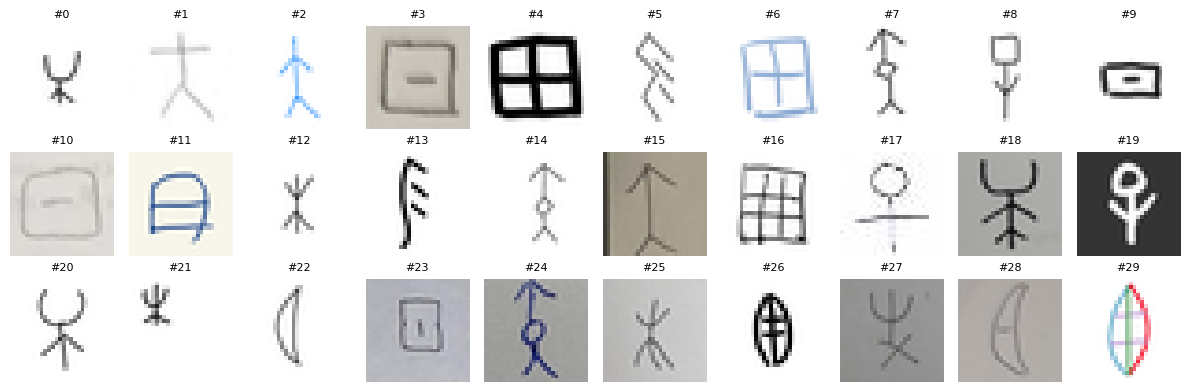

In [4]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i])
    ax.set_title(f"#{i}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Simple statistics of the whole file

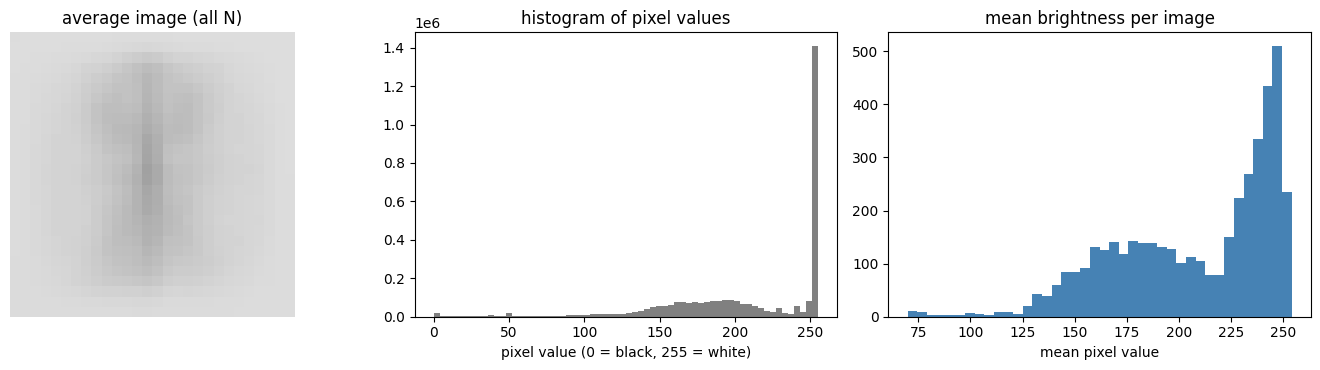

images with colored ink or background (mean channel spread > 10): 688 / 4320


In [5]:
gray = images.astype(np.float32).mean(axis=-1)      # N x 28 x 28

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].imshow(gray.mean(axis=0), cmap="gray", vmin=0, vmax=255)
axes[0].set_title("average image (all N)")
axes[0].axis("off")

axes[1].hist(gray.ravel(), bins=64, color="gray")
axes[1].set_title("histogram of pixel values")
axes[1].set_xlabel("pixel value (0 = black, 255 = white)")

axes[2].hist(gray.reshape(N, -1).mean(axis=1), bins=40, color="steelblue")
axes[2].set_title("mean brightness per image")
axes[2].set_xlabel("mean pixel value")
plt.tight_layout()
plt.show()

color = (images.max(axis=-1).astype(int) - images.min(axis=-1)).reshape(N, -1).mean(axis=1)
print(f"images with colored ink or background (mean channel spread > 10): {(color > 10).sum()} / {N}")

The brightest and darkest images. These are the ones where the conversion of Q2a matters most.

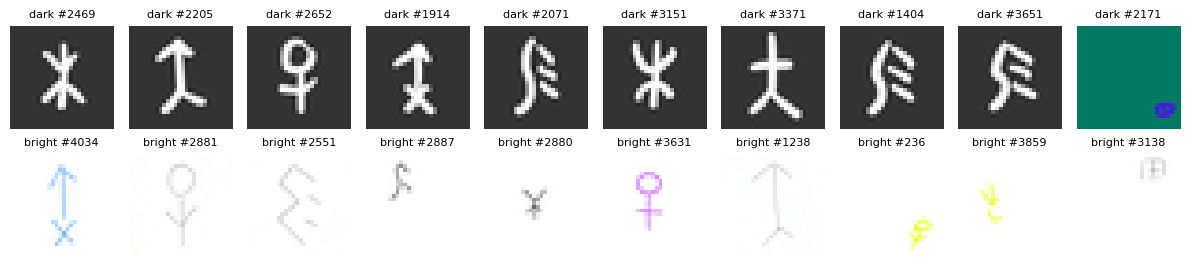

In [6]:
order = np.argsort(gray.reshape(N, -1).mean(axis=1))
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, i in zip(axes[0], order[:10]):
    ax.imshow(images[i]); ax.set_title(f"dark #{i}", fontsize=8); ax.axis("off")
for ax, i in zip(axes[1], order[-10:]):
    ax.imshow(images[i]); ax.set_title(f"bright #{i}", fontsize=8); ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Save your predictions

Replace `predict` below with your network from Q1b and the conversion from Q2a.
The placeholder only returns random labels so that this notebook runs end to end.
Do not label images by hand, and do not train on this file.

In [7]:
def predict(images):
    """images: N x 28 x 28 x 3 uint8 -> N integer labels in 0..9.
    Replace this with: your Q2a conversion -> your Q1b network -> argmax."""
    return np.random.default_rng(0).integers(0, 10, size=len(images))   # placeholder

pred = np.asarray(predict(images)).astype(np.int64)

In [8]:
def check_prediction(pred, n_images):
    pred = np.asarray(pred)
    assert pred.shape == (n_images,), f"need one prediction per image: shape ({n_images},), got {pred.shape}"
    assert np.issubdtype(pred.dtype, np.integer), f"need integer labels, got {pred.dtype}"
    assert pred.min() >= 0 and pred.max() <= 9, "labels must be in 0..9"
    print("OK:", pred.shape, pred.dtype, "  predicted count per class:", np.bincount(pred, minlength=10))

check_prediction(pred, N)
out = f"HW3_prediction_{STUDENT_ID}.npy"
np.save(out, pred)

# read it back exactly as the TAs will
back = np.load(out)
check_prediction(back, N)
print("saved", out)

OK: (4320,) int64   predicted count per class: [446 434 408 428 426 446 414 408 448 462]
OK: (4320,) int64   predicted count per class: [446 434 408 428 426 446 414 408 448 462]
saved HW3_prediction_113000000.npy
